# Practical 1E — Sign MNIST Fully Connected Neural Network

Extracted from `1E.pdf`. Original displayed outputs omitted; executable Python code retained.

**Required local inputs:** `sign_mnist_test.csv`, `sign_mnist_train.csv`

Training data: (27455, 784)
Testing data: (7172, 784)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 25)                  │           1,625 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,361 (431.10 KB)

 Trainable params: 110,361 (431.10 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.2582 - loss: 2.4493 - val_accuracy: 0.5371 - val_loss: 1.5888
Epoch 2/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.5592 - loss: 1.3837 - val_accuracy: 0.6373 - val_loss: 1.1473
Epoch 3/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.6618 - loss: 1.0414 - val_accuracy: 0.7141 - val_loss: 0.8918
Epoch 4/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.7392 - loss: 0.8065 - val_accuracy: 0.8125 - val_loss: 0.6480
Epoch 5/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.7970 - loss: 0.6360 - val_accuracy: 0.8383 - val_loss: 0.5230
Epoch 6/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8420 - loss: 0.5068 - val_accuracy: 0.8966 - val_loss: 0.3801
Epoch 7/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8757 - loss: 0.4061 - val_accuracy: 0.8616 - val_loss: 0.3970
Epoch 8/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.9056 - loss: 0.3136 - val_accuracy: 

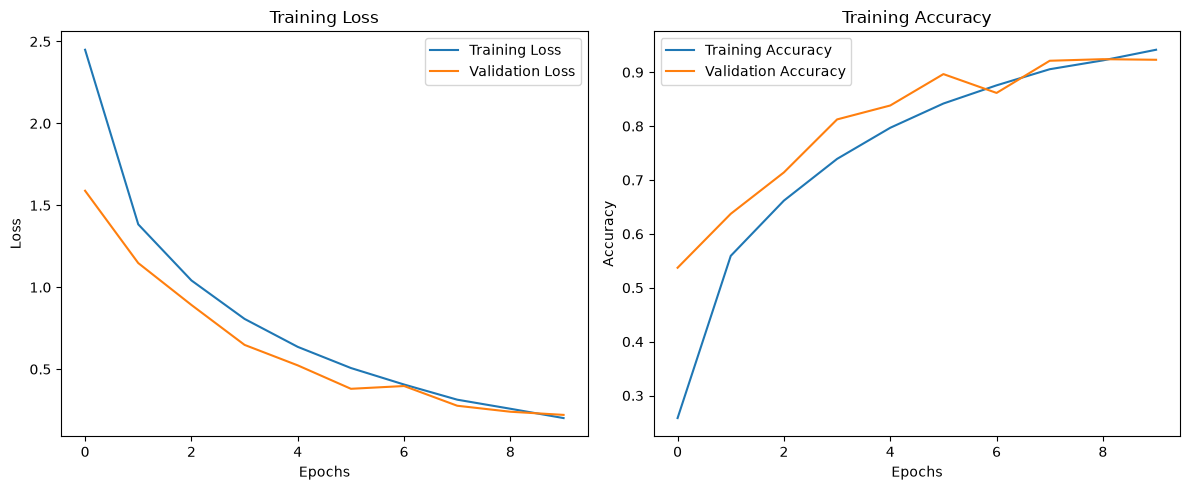

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
train = pd.read_csv('LP_IV_Updated Datasets/LP_IV_Updated Datasets/FNN and CNN/Sign Language MNIST/sign_mnist_train.csv')
test = pd.read_csv('LP_IV_Updated Datasets/LP_IV_Updated Datasets/FNN and CNN/Sign Language MNIST/sign_mnist_test.csv')
X_train = train.drop('label', axis=1).values
y_train = train['label'].values
X_test = test.drop('label', axis=1).values
y_test = test['label'].values
X_train = X_train / 255.0
X_test = X_test / 255.0
print('Training data:', X_train.shape)
print('Testing data:', X_test.shape)
model = Sequential([
    Input(shape=(784,)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(25, activation='softmax')
])
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()
history = model.fit(
    X_train, y_train,
    epochs=10, batch_size=32, validation_split=0.1
)
loss, accuracy = model.evaluate(X_test, y_test)
print('Test Loss:', loss)
print('Test Accuracy:', accuracy * 100, '%')
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()
